# Nuclear Half-Life Prediction — Included NaN

This notebook evaluates regression models that can natively handle missing feature values without imputation or row removal.

Models:
- Dummy Regressor
- Decision Tree Regressor
- Random Forest Regressor
- XGBoost Regressor

In [3]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_validate
)

from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    max_error
)

from xgboost import XGBRegressor
import xgboost as xgb


# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


# Environment check
print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgb.__version__)
print("Random seed:", RANDOM_SEED)

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
scikit-learn: 1.9.1
XGBoost: 3.4.1
Random seed: 42


## 2. Load Dataset

Load the extracted ENSDF dataset while preserving missing feature values.

In [4]:
# Import Data
DATA_DIR = Path.cwd().parent / "Extraction"
INPUT_FILE = DATA_DIR / "extracted_data.csv"

df = pd.read_csv(INPUT_FILE, keep_default_na=False, na_values=[""])

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (3371, 20)


,nuclide,element,Z,A,N,dataset_name,ground_energy_keV,spin_parity_raw,half_life_raw,half_life_value,half_life_unit,half_life_seconds,half_life_status,Q_beta_keV,S_n_keV,S_p_keV,Q_alpha_keV,ground_state_ambiguous,ground_state_candidate_count,source_file
0,1H,H,1,1,0,ADOPTED LEVELS,0.0,1/2+,STABLE,NaN,NaN,NaN,stable,NaN,NaN,NaN,NaN,False,1,ensdf.001
1,2H,H,1,2,1,ADOPTED LEVELS,0.0,1+,STABLE,NaN,NaN,NaN,stable,NaN,2224.566,2224.566,1.0,False,1,ensdf.002
2,3H,H,1,3,2,ADOPTED LEVELS,0.0,1/2+,12.32 Y,12.32,Y,388789632.0,finite,18.5906,6257.233,NaN,NaN,False,1,ensdf.003
3,3HE,HE,2,3,1,ADOPTED LEVELS,0.0,1/2+,STABLE,NaN,NaN,NaN,stable,NaN,NaN,5493.477,NaN,False,1,ensdf.003
4,4H,H,1,4,3,ADOPTED LEVELS,0.0,2-,NaN,NaN,NaN,NaN,missing,NaN,NaN,NaN,NaN,False,1,ensdf.004


In [5]:
# 3. Prepare target
# Keep finite half-lives and use log10(seconds) as the target.

reg_df = df[df["half_life_status"] == "finite"].copy()

reg_df["log_half_life"] = np.log10(
    reg_df["half_life_seconds"]
)

print("Finite half-life samples:", len(reg_df))
display(reg_df[["nuclide", "half_life_seconds", "log_half_life"]].head())

Finite half-life samples: 2796


,nuclide,half_life_seconds,log_half_life
2,3H,3.887896e+08,8.589715
11,6HE,8.067000e-01,-0.093288
17,7BE,4.598208e+06,6.662589
19,8HE,1.191000e-01,-0.924088
20,8LI,8.399000e-01,-0.075772


In [6]:
# 4. Define features
# Use A, N/Z, Qβ, Qα, Sn, and Sp. Keep NaN values unchanged.

reg_df["N/Z"] = reg_df["N"] / reg_df["Z"]

FEATURES = [
    "A",
    "N/Z",
    "Q_beta_keV",
    "Q_alpha_keV",
    "S_n_keV",
    "S_p_keV"
]

TARGET = "log_half_life"

X = reg_df[FEATURES].copy()
y = reg_df[TARGET].copy()

print("Features:", FEATURES)
print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())

Features: ['A', 'N/Z', 'Q_beta_keV', 'Q_alpha_keV', 'S_n_keV', 'S_p_keV']
X shape: (2796, 6)
y shape: (2796,)


,A,N/Z,Q_beta_keV,Q_alpha_keV,S_n_keV,S_p_keV
2,3,2.000000,18.5906,NaN,6257.233,NaN
11,6,2.000000,3505.2200,NaN,1710.000,NaN
17,7,0.750000,NaN,-1587.13,10677.000,5606.85
19,8,3.000000,10663.8800,NaN,2535.000,NaN
20,8,1.666667,16004.1300,NaN,2032.620,12416.00


In [7]:
# 5. Check missing values
# Confirm that NaN values are retained in the Included-NaN dataset.

missing_summary = pd.DataFrame({
    "Missing count": X.isna().sum(),
    "Missing (%)": X.isna().mean() * 100
})

display(missing_summary)

,Missing count,Missing (%)
A,0,0.000000
N/Z,0,0.000000
Q_beta_keV,826,29.542203
Q_alpha_keV,615,21.995708
S_n_keV,624,22.317597
S_p_keV,630,22.532189


In [8]:
# 6. Train-test split
# Use the same 80:20 split and random seed for reproducibility.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_SEED
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nMissing values in training set:")
display(X_train.isna().sum())

print("Missing values in test set:")
display(X_test.isna().sum())

Training samples: 2236
Test samples: 560

Missing values in training set:


A                0
N/Z              0
Q_beta_keV     662
Q_alpha_keV    488
S_n_keV        489
S_p_keV        490
dtype: int64

Missing values in test set:


A                0
N/Z              0
Q_beta_keV     164
Q_alpha_keV    127
S_n_keV        135
S_p_keV        140
dtype: int64

In [9]:
# 7. Evaluation function
# Use the same metrics for every model.

def evaluate_regression(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    maximum_error = max_error(y_true, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Max Error": maximum_error
    }

In [10]:
# 8. Dummy baselines
# Evaluate mean and median baselines using 5-fold CV on the training set.

dummy_mean = DummyRegressor(strategy="mean")
dummy_median = DummyRegressor(strategy="median")

dummy_mean_cv = cross_validate(
    dummy_mean,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

dummy_median_cv = cross_validate(
    dummy_median,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

dummy_results = pd.DataFrame({
    "Model": ["Dummy Mean", "Dummy Median"],
    "CV MAE": [
        -dummy_mean_cv["test_score"].mean(),
        -dummy_median_cv["test_score"].mean()
    ]
})

display(dummy_results)

,Model,CV MAE
0,Dummy Mean,2.403674
1,Dummy Median,2.402302


In [11]:
# 9. Decision Tree baseline
# Evaluate the default tree using 5-fold CV on the training set.

dt_baseline = DecisionTreeRegressor(
    random_state=RANDOM_SEED
)

dt_baseline_cv = cross_validate(
    dt_baseline,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

dt_baseline_cv_mae = -dt_baseline_cv["test_score"].mean()

print("Decision Tree baseline CV MAE:")
print(dt_baseline_cv_mae)

Decision Tree baseline CV MAE:
1.2544479904853965


In [12]:
# 10. Decision Tree tuning
# Use 5-fold CV and MAE to control tree complexity.

dt_param_grid = {
    "max_depth": [3, 5, 10, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5, 10]
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeRegressor(
        random_state=RANDOM_SEED
    ),
    param_grid=dt_param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

dt_grid.fit(X_train, y_train)

print("Best parameters:")
print(dt_grid.best_params_)

print("\nBest CV MAE:")
print(-dt_grid.best_score_)

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10}

Best CV MAE:
1.2338076445666213


In [13]:
# 11. Select tuned Decision Tree
# Store the best model selected by training-set cross-validation.

dt_best = dt_grid.best_estimator_

print("Best Decision Tree parameters:")
print(dt_grid.best_params_)

print("\nBest Decision Tree CV MAE:")
print(-dt_grid.best_score_)

Best Decision Tree parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10}

Best Decision Tree CV MAE:
1.2338076445666213


In [14]:
# 12. Random Forest baseline
# Use the course baseline settings and evaluate with 5-fold CV.

rf_baseline = RandomForestRegressor(
    n_estimators=100,
    max_features=0.5,
    min_samples_leaf=3,
    random_state=RANDOM_SEED,
    n_jobs=-1
)

rf_baseline_cv = cross_validate(
    rf_baseline,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

rf_baseline_cv_mae = -rf_baseline_cv["test_score"].mean()

print("Random Forest baseline CV MAE:")
print(rf_baseline_cv_mae)

Random Forest baseline CV MAE:
1.0047094571680422


In [15]:
# 13. Random Forest tuning
# Tune the main RF hyperparameters using 5-fold CV and MAE.

rf_param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [10, 20, None],
    "max_features": [0.3, 0.5],
    "min_samples_leaf": [1, 2]
}

rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=RANDOM_SEED,
        n_jobs=-1
    ),
    param_grid=rf_param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best parameters:")
print(rf_grid.best_params_)

print("\nBest CV MAE:")
print(-rf_grid.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters:
{'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 500}

Best CV MAE:
0.9663464306704903


In [16]:
# 14. Refine Random Forest tuning
# Search around the best parameters from the first grid.

rf_refined_grid = {
    "n_estimators": [500, 800],
    "max_depth": [30, None],
    "max_features": [0.5, 0.7],
    "min_samples_leaf": [1, 2]
}

rf_refined = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=RANDOM_SEED,
        n_jobs=-1
    ),
    param_grid=rf_refined_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

rf_refined.fit(X_train, y_train)

print("Best parameters:")
print(rf_refined.best_params_)

print("\nBest CV MAE:")
print(-rf_refined.best_score_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters:
{'max_depth': 30, 'max_features': 0.7, 'min_samples_leaf': 1, 'n_estimators': 800}

Best CV MAE:
0.9634511856929461


In [17]:
# 15. Select tuned Random Forest
# Store the best RF selected by training-set cross-validation.

rf_best = rf_refined.best_estimator_

print("Best Random Forest parameters:")
print(rf_refined.best_params_)

print("\nBest Random Forest CV MAE:")
print(-rf_refined.best_score_)

Best Random Forest parameters:
{'max_depth': 30, 'max_features': 0.7, 'min_samples_leaf': 1, 'n_estimators': 800}

Best Random Forest CV MAE:
0.9634511856929461


In [18]:
# 16. XGBoost baseline
# Evaluate the default XGBoost model using 5-fold CV.

xgb_baseline = XGBRegressor(
    objective="reg:squarederror",
    random_state=RANDOM_SEED,
    n_jobs=-1
)

xgb_baseline_cv = cross_validate(
    xgb_baseline,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

xgb_baseline_cv_mae = -xgb_baseline_cv["test_score"].mean()

print("XGBoost baseline CV MAE:")
print(xgb_baseline_cv_mae)

XGBoost baseline CV MAE:
0.9856344126639767


In [19]:
# 17. XGBoost tuning
# Tune the main XGBoost hyperparameters using 5-fold CV and MAE.

xgb_param_grid = {
    "n_estimators": [300, 500, 800],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.05, 0.1]
}

xgb_grid = GridSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=RANDOM_SEED,
        n_jobs=1
    ),
    param_grid=xgb_param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

xgb_grid.fit(X_train, y_train)

print("Best parameters:")
print(xgb_grid.best_params_)

print("\nBest CV MAE:")
print(-xgb_grid.best_score_)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best parameters:
{'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 800}

Best CV MAE:
0.9471939253872497


In [20]:
# 18. Refine XGBoost tuning
# Search around the best parameters from the first grid.

xgb_refined_grid = {
    "n_estimators": [800, 1200],
    "max_depth": [7, 9],
    "learning_rate": [0.03, 0.05, 0.07]
}

xgb_refined = GridSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=RANDOM_SEED,
        n_jobs=1
    ),
    param_grid=xgb_refined_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

xgb_refined.fit(X_train, y_train)

print("Best refined parameters:")
print(xgb_refined.best_params_)

print("\nBest refined CV MAE:")
print(-xgb_refined.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best refined parameters:
{'learning_rate': 0.07, 'max_depth': 7, 'n_estimators': 800}

Best refined CV MAE:
0.9454641085272556


In [21]:
# 19. Final XGBoost test evaluation
# Evaluate the CV-selected XGBoost model once on the test set.

xgb_best = xgb_refined.best_estimator_

xgb_best_train_pred = xgb_best.predict(X_train)
xgb_best_test_pred = xgb_best.predict(X_test)

xgb_best_results = pd.DataFrame(
    {
        "Train": evaluate_regression(y_train, xgb_best_train_pred),
        "Test": evaluate_regression(y_test, xgb_best_test_pred)
    }
).T

display(xgb_best_results)

print("Best XGBoost parameters:")
print(xgb_refined.best_params_)

print("\nBest XGBoost CV MAE:")
print(-xgb_refined.best_score_)

,MAE,MSE,RMSE,R2,Max Error
Train,0.035258,0.003661,0.060504,0.999642,0.532862
Test,0.904116,2.002512,1.415101,0.807087,6.382270


Best XGBoost parameters:
{'learning_rate': 0.07, 'max_depth': 7, 'n_estimators': 800}

Best XGBoost CV MAE:
0.9454641085272556


In [22]:
# 20. Final model comparison
# Compare the tuned models on the same test set.

dt_final_pred = dt_best.predict(X_test)
rf_final_pred = rf_best.predict(X_test)
xgb_final_pred = xgb_best.predict(X_test)

final_results = pd.DataFrame({
    "Decision Tree": evaluate_regression(y_test, dt_final_pred),
    "Random Forest": evaluate_regression(y_test, rf_final_pred),
    "XGBoost": evaluate_regression(y_test, xgb_final_pred)
}).T

final_results = final_results.sort_values("MAE")

display(final_results)

,MAE,MSE,RMSE,R2,Max Error
Random Forest,0.893300,1.900677,1.378650,0.816897,5.572244
XGBoost,0.904116,2.002512,1.415101,0.807087,6.382270
Decision Tree,1.272069,3.908291,1.976940,0.623492,9.353477


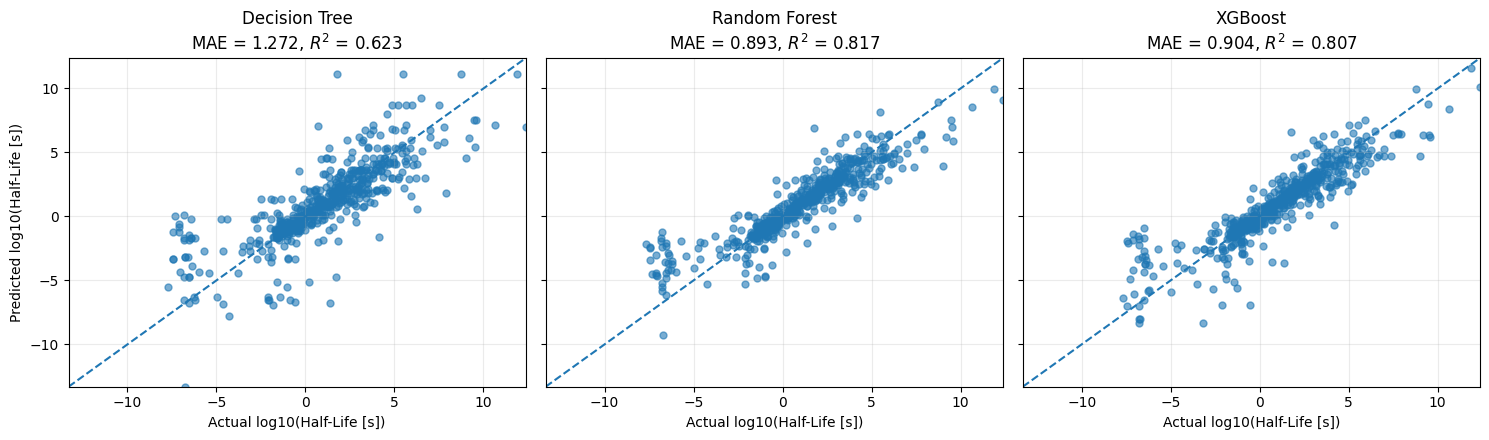

In [23]:
# 21. Parity plots
# Compare actual and predicted test values for all tuned models.

predictions = {
    "Decision Tree": dt_final_pred,
    "Random Forest": rf_final_pred,
    "XGBoost": xgb_final_pred
}

all_values = np.concatenate([
    y_test.to_numpy(),
    dt_final_pred,
    rf_final_pred,
    xgb_final_pred
])

plot_min = all_values.min()
plot_max = all_values.max()

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.5),
    sharex=True,
    sharey=True
)

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    results = evaluate_regression(y_test, y_pred)

    ax.scatter(
        y_test,
        y_pred,
        alpha=0.6,
        s=25
    )

    ax.plot(
        [plot_min, plot_max],
        [plot_min, plot_max],
        linestyle="--"
    )

    ax.set_title(
        f"{model_name}\n"
        f"MAE = {results['MAE']:.3f}, "
        f"$R^2$ = {results['R2']:.3f}"
    )

    ax.set_xlabel("Actual log10(Half-Life [s])")
    ax.set_xlim(plot_min, plot_max)
    ax.set_ylim(plot_min, plot_max)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Predicted log10(Half-Life [s])")

plt.tight_layout()
plt.show()

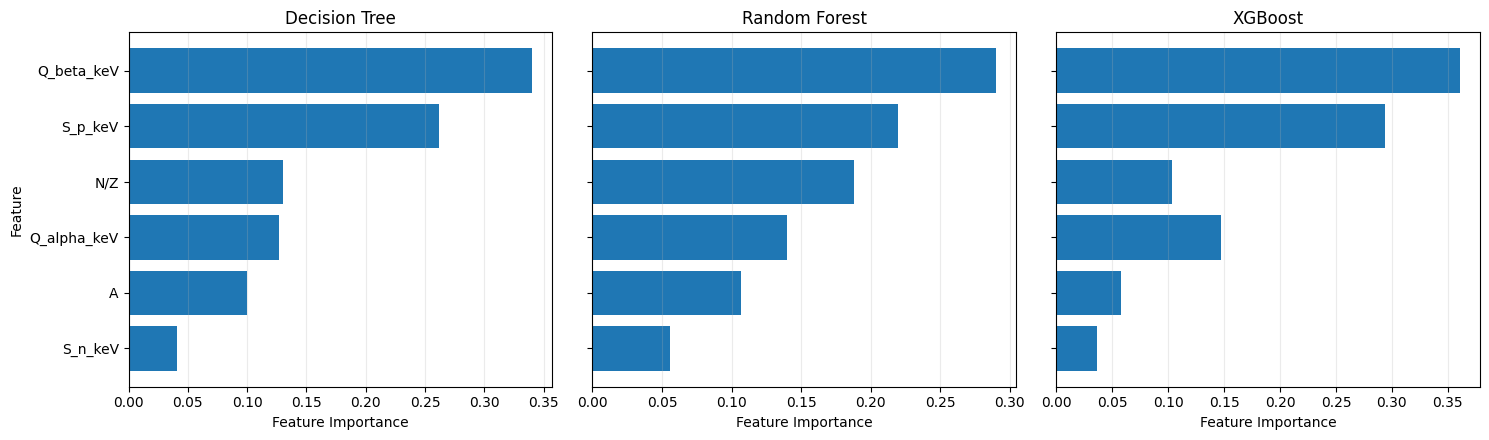

In [24]:
# 22. Feature importance
# Compare the relative feature importance of the tuned tree-based models.

models = {
    "Decision Tree": dt_best,
    "Random Forest": rf_best,
    "XGBoost": xgb_best
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.5),
    sharey=True
)

for ax, (model_name, model) in zip(axes, models.items()):
    importance_df = pd.DataFrame({
        "Feature": FEATURES,
        "Importance": model.feature_importances_
    }).sort_values(
        "Importance",
        ascending=True
    )

    ax.barh(
        importance_df["Feature"],
        importance_df["Importance"]
    )

    ax.set_title(model_name)
    ax.set_xlabel("Feature Importance")
    ax.grid(
        axis="x",
        alpha=0.25
    )

axes[0].set_ylabel("Feature")

plt.tight_layout()
plt.show()

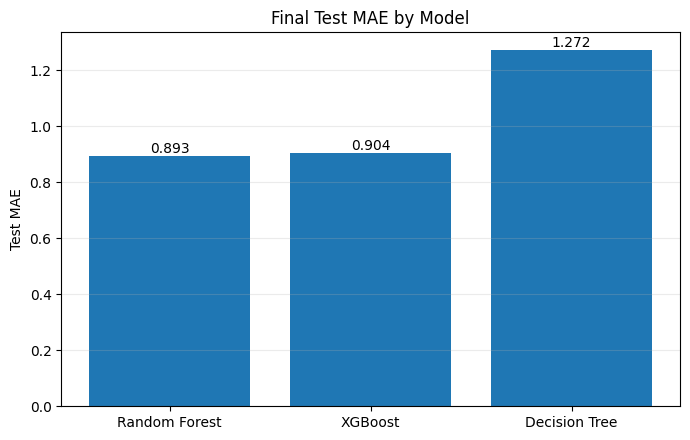

In [25]:
# 23. Test MAE comparison
# Compare final test MAE across the tuned models.

mae_comparison = final_results["MAE"].sort_values()

plt.figure(figsize=(7, 4.5))

bars = plt.bar(
    mae_comparison.index,
    mae_comparison.values
)

plt.ylabel("Test MAE")
plt.title("Final Test MAE by Model")
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, mae_comparison.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [26]:
# 24. Final summary
# Summarize the best models, CV performance, and final test results.

summary_table = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "Best CV MAE": [
        -dt_grid.best_score_,
        -rf_refined.best_score_,
        -xgb_refined.best_score_
    ],
    "Test MAE": [
        final_results.loc["Decision Tree", "MAE"],
        final_results.loc["Random Forest", "MAE"],
        final_results.loc["XGBoost", "MAE"]
    ],
    "Test RMSE": [
        final_results.loc["Decision Tree", "RMSE"],
        final_results.loc["Random Forest", "RMSE"],
        final_results.loc["XGBoost", "RMSE"]
    ],
    "Test R2": [
        final_results.loc["Decision Tree", "R2"],
        final_results.loc["Random Forest", "R2"],
        final_results.loc["XGBoost", "R2"]
    ],
    "Test Max Error": [
        final_results.loc["Decision Tree", "Max Error"],
        final_results.loc["Random Forest", "Max Error"],
        final_results.loc["XGBoost", "Max Error"]
    ]
})

summary_table = summary_table.sort_values(
    "Test MAE"
).reset_index(drop=True)

display(summary_table)

print("\nBest model on the Included-NaN test set:")
print(summary_table.loc[0, "Model"])

,Model,Best CV MAE,Test MAE,Test RMSE,Test R2,Test Max Error
0,Random Forest,0.963451,0.893300,1.378650,0.816897,5.572244
1,XGBoost,0.945464,0.904116,1.415101,0.807087,6.382270
2,Decision Tree,1.233808,1.272069,1.976940,0.623492,9.353477



Best model on the Included-NaN test set:
Random Forest
